# Previsão de Churn em Operadora de Telecomunicações

C318 – Fundamentos de Machine Learning (Inatel). Escopo e decisões: [`BACKLOG.md`](BACKLOG.md) e [`DECISION_LOG.md`](DECISION_LOG.md).

## 1. Dados e limpeza

- `customerID` é removido, pois é só um identificador.
- `TotalCharges` vem como texto; os 11 brancos são clientes com `tenure = 0` (ainda não pagaram nada) e recebem 0 (D-08).
- `Churn` vira 0/1 (1 = cancelou).
- **Não** padronizamos `SeniorCitizen` nem fundimos "No internet service" com "No": o one-hot encoding já trata essas colunas sem perda (D-09).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42                      # mesma semente em todo o projeto
os.makedirs('figures', exist_ok=True)  # destino das figuras usadas nos slides

In [2]:
df = pd.read_csv('data/Telco-Customer-Churn.csv')
df = df.drop(columns='customerID')
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges vem como texto; os brancos (" ") viram NaN na conversão
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
nulos = df['TotalCharges'].isna()
n_nulos = nulos.sum()
tenure_dos_nulos = df.loc[nulos, 'tenure']
df['TotalCharges'] = df['TotalCharges'].fillna(0)  # D-08: cliente novo, ainda não pagou

df['Churn'] = (df['Churn'] == 'Yes').astype(int)   # alvo binário: 1 = cancelou

In [4]:
# Checagens de controle (D-07)
assert len(df) == 7043, 'número de clientes inesperado'
assert n_nulos == 11, 'número de brancos em TotalCharges inesperado'
assert (tenure_dos_nulos == 0).all(), 'brancos deveriam ser só clientes novos'
assert 0.26 < df['Churn'].mean() < 0.27, 'taxa de churn fora do esperado'
print(f"Clientes: {len(df)} | Taxa de churn: {df['Churn'].mean():.1%}")

Clientes: 7043 | Taxa de churn: 26.5%


## 2. Análise exploratória

Objetivo: responder **"Por que cancelam?"** (pergunta 2) e **"Quem é o cliente de risco?"** (pergunta 3), verificando as 5 hipóteses da proposta. A linha tracejada nos gráficos é a taxa geral de churn.

In [5]:
taxa_geral = df['Churn'].mean()
print(f'Taxa geral de churn: {taxa_geral:.1%}')

Taxa geral de churn: 26.5%


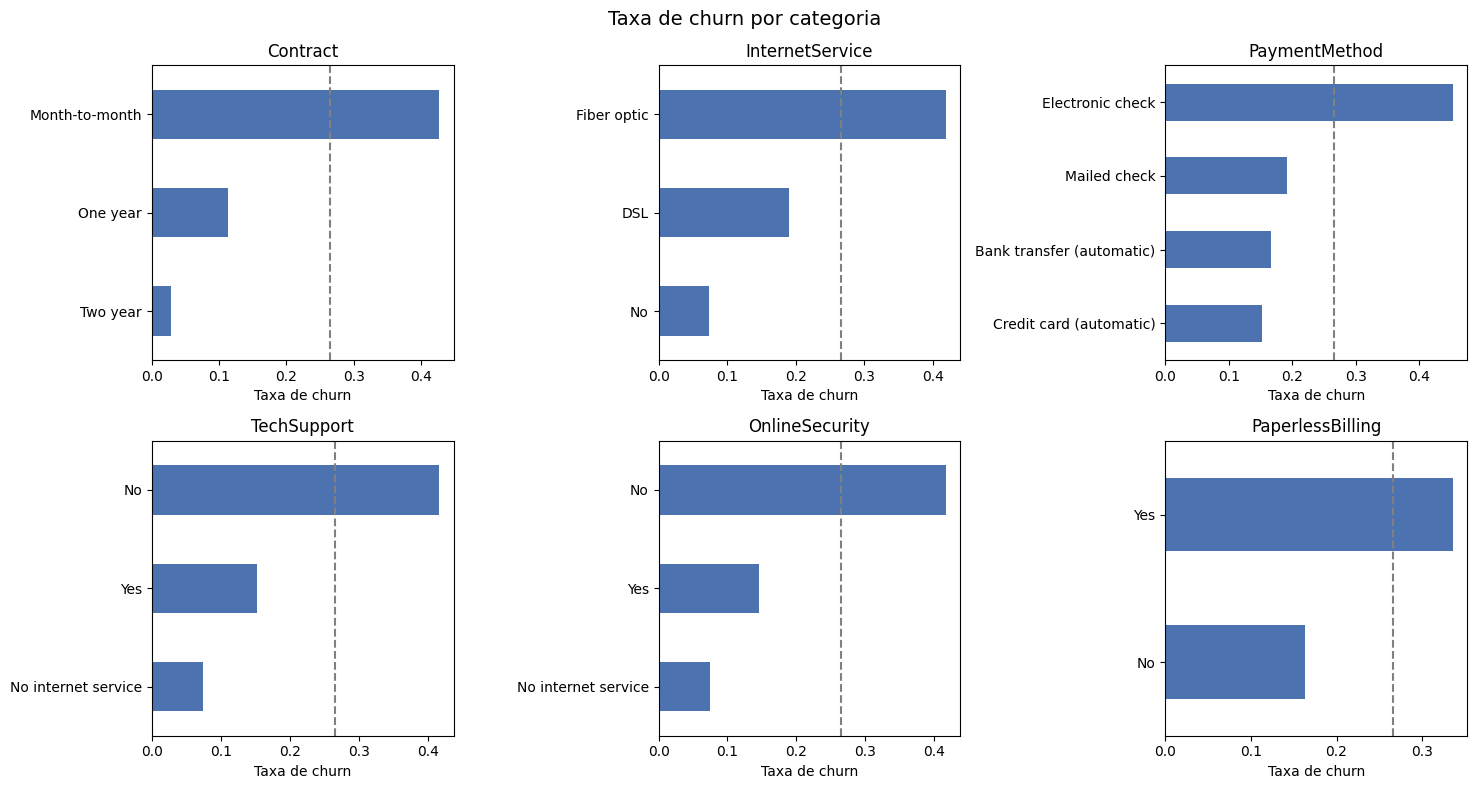

In [6]:
cats = ['Contract', 'InternetService', 'PaymentMethod',
        'TechSupport', 'OnlineSecurity', 'PaperlessBilling']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cats):
    df.groupby(col)['Churn'].mean().sort_values().plot.barh(ax=ax, color='#4C72B0')
    ax.axvline(taxa_geral, ls='--', color='gray')   # referência: média geral
    ax.set_title(col)
    ax.set_xlabel('Taxa de churn')
    ax.set_ylabel('')
fig.suptitle('Taxa de churn por categoria', fontsize=14)
fig.tight_layout()
fig.savefig('figures/01_churn_por_categoria.png', dpi=150, bbox_inches='tight')
plt.show()

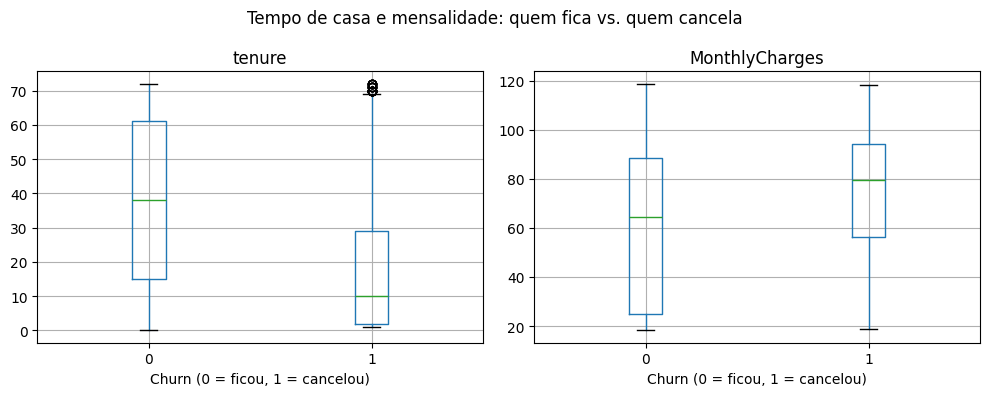

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges']):
    df.boxplot(column=col, by='Churn', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Churn (0 = ficou, 1 = cancelou)')
fig.suptitle('Tempo de casa e mensalidade: quem fica vs. quem cancela')
fig.tight_layout()
fig.savefig('figures/02_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Perfil: cliente típico de cada classe
moda = lambda s: s.mode()[0]
perfil = df.groupby('Churn').agg(
    clientes=('Churn', 'size'),
    tenure=('tenure', 'mean'),
    MonthlyCharges=('MonthlyCharges', 'mean'),
    TotalCharges=('TotalCharges', 'mean'),
    Contract=('Contract', moda),
    InternetService=('InternetService', moda),
    PaymentMethod=('PaymentMethod', moda),
).round(1)
perfil

,clientes,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod
Churn,,,,,,,
0,5174,37.6,61.3,2549.9,Month-to-month,DSL,Mailed check
1,1869,18.0,74.4,1531.8,Month-to-month,Fiber optic,Electronic check


In [9]:
# Hipóteses: churn do grupo de risco vs. grupo de comparação
def taxa(mask):
    return df.loc[mask, 'Churn'].mean()

hipoteses = {
    'H1 Contrato mensal':      (df.Contract == 'Month-to-month',        df.Contract != 'Month-to-month'),
    'H2 Cliente novo (≤12m)':  (df.tenure <= 12,                        df.tenure > 12),
    'H3 Fibra óptica':         (df.InternetService == 'Fiber optic',    df.InternetService == 'DSL'),
    'H4 Sem suporte técnico':  (df.TechSupport == 'No',                 df.TechSupport == 'Yes'),
    'H4 Sem segurança online': (df.OnlineSecurity == 'No',              df.OnlineSecurity == 'Yes'),
    'H5 Electronic check':     (df.PaymentMethod == 'Electronic check', df.PaymentMethod != 'Electronic check'),
}
tab = pd.DataFrame([(h, taxa(r), taxa(c)) for h, (r, c) in hipoteses.items()],
                   columns=['hipotese', 'churn_risco', 'churn_comparacao'])
tab['razao'] = tab.churn_risco / tab.churn_comparacao
tab['veredito'] = np.where(tab.razao >= 1.5, 'Confirmada', 'Não confirmada')
tab.style.format({'churn_risco': '{:.1%}', 'churn_comparacao': '{:.1%}', 'razao': '{:.1f}x'})

,hipotese,churn_risco,churn_comparacao,razao,veredito
0,H1 Contrato mensal,42.7%,6.8%,6.3x,Confirmada
1,H2 Cliente novo (≤12m),47.4%,17.1%,2.8x,Confirmada
2,H3 Fibra óptica,41.9%,19.0%,2.2x,Confirmada
3,H4 Sem suporte técnico,41.6%,15.2%,2.7x,Confirmada
4,H4 Sem segurança online,41.8%,14.6%,2.9x,Confirmada
5,H5 Electronic check,45.3%,17.1%,2.7x,Confirmada


### Leitura dos resultados

**As 5 hipóteses foram confirmadas.** Em todas, o grupo de risco tem 2 a 6 vezes o churn do grupo de comparação.

**Por que cancelam? (pergunta 2)**
- **Falta de compromisso contratual** é o fator mais forte. O contrato mensal tem 42,7% de churn, contra 6,8% nos contratos de 1 ou 2 anos (6,3×).
- **O primeiro ano é o período crítico.** Clientes com até 12 meses de casa cancelam 47,4%, contra 17,1% dos demais. Quem cancela tem mediana de 10 meses de casa, contra 38 de quem fica.
- **Fibra óptica** tem 41,9% de churn, contra 19,0% do DSL. É também o plano mais caro, e quem cancela paga em média mais (US\$ 74 contra US\$ 61). Os dados não permitem separar se a causa é preço ou qualidade.
- **Falta de serviços de proteção e suporte.** Sem suporte técnico, o churn é 41,6% (contra 15,2% com suporte). Sem segurança online, 41,8% (contra 14,6%).
- **Pagamento por *electronic check*** tem 45,3% de churn, contra 17,1% das outras formas. As formas automáticas (cartão e débito em conta) têm as menores taxas.
- Observado sem hipótese prévia: clientes com **fatura digital** cancelam o dobro (33,6% contra 16,3%).

**Quem é o cliente de risco? (pergunta 3)**
Contrato mensal, no primeiro ano de casa, internet de fibra, mensalidade acima da média, pagamento por *electronic check* e sem serviços de suporte ou segurança. O contrato mensal aparece como moda nas duas classes porque é o mais comum na base (55% dos clientes). A diferença entre as classes está na **taxa**, não na moda.

**Cuidados:**
- São **associações, não causas**, e os fatores se sobrepõem (por exemplo, clientes novos tendem a estar no contrato mensal). A seção 3 avalia o peso conjunto deles no modelo.
- `TotalCharges` é basicamente `tenure × MonthlyCharges` (correlação de 0,83 com `tenure`) e não traz informação nova (D-11). A coluna é mantida no modelo porque não prejudica a regressão regularizada nem as árvores.

## 3. Modelagem

Objetivo: responder **"Quem vai cancelar?"** (pergunta 1).

- Treino/teste 80/20 estratificado. O teste só é usado na avaliação do modelo final.
- Um único pré-processamento dentro do pipeline: one-hot nas categóricas e padronização nas numéricas. Por estar no pipeline, ele é aprendido só com os dados de treino de cada fold (D-15).
- 3 modelos com `class_weight='balanced'` para compensar o desbalanceamento (D-12, D-14), ajustados por `GridSearchCV` com 5 folds estratificados, otimizando ROC-AUC (D-16).

In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score, ConfusionMatrixDisplay)

In [11]:
X, y = df.drop(columns='Churn'), df['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat = [c for c in X.columns if c not in num]
pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat),
                         ('num', StandardScaler(), num)])

print(f'Treino: {len(X_train)} clientes ({y_train.mean():.1%} churn) | '
      f'Teste: {len(X_test)} clientes ({y_test.mean():.1%} churn)')

Treino: 5634 clientes (26.5% churn) | Teste: 1409 clientes (26.5% churn)


In [12]:
modelos = {
    'Regressão Logística': (LogisticRegression(class_weight='balanced', max_iter=1000),
                            {'clf__C': [0.01, 0.1, 1, 10]}),
    'Árvore de Decisão':   (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                            {'clf__max_depth': [3, 5, 8], 'clf__min_samples_leaf': [1, 20, 50]}),
    'Random Forest':       (RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                   n_jobs=-1, random_state=RANDOM_STATE),
                            {'clf__max_depth': [None, 8, 12], 'clf__min_samples_leaf': [1, 5]}),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

buscas = {}
for nome, (clf, grade) in modelos.items():
    busca = GridSearchCV(Pipeline([('pre', pre), ('clf', clf)]), grade,
                         cv=cv, scoring='roc_auc', n_jobs=-1)
    buscas[nome] = busca.fit(X_train, y_train)

comparacao = pd.DataFrame({
    nome: {'auc_cv': b.best_score_,
           'desvio': b.cv_results_['std_test_score'][b.best_index_],
           'melhores_parametros': {k.replace('clf__', ''): v for k, v in b.best_params_.items()}}
    for nome, b in buscas.items()}).T.sort_values('auc_cv', ascending=False)
comparacao

,auc_cv,desvio,melhores_parametros
Random Forest,0.847094,0.009206,"{'max_depth': 8, 'min_samples_leaf': 5}"
Regressão Logística,0.846226,0.012708,{'C': 10}
Árvore de Decisão,0.830999,0.014418,"{'max_depth': 5, 'min_samples_leaf': 50}"
